# Phylogenetic Tree - HvCESA & Reference Species
**Sequences:** HvCESA1-7 (7), AtCESA1-10 (10), OsCESA1-9 (9), ZmCESA1-12 (12) = 38 total  
**Pipeline:** MAFFT alignment → IQ-TREE inference → Bio.Phylo visualization  
**No new installations required**

In [1]:
# STEP 1: Imports - all already installed
from Bio import Phylo
from Bio.Phylo.BaseTree import Tree
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import subprocess
import os
print('All imports successful')
print(f'Biopython: {__import__("Bio").__version__}')
print(f'Matplotlib: {matplotlib.__version__}')

All imports successful
Biopython: 1.87
Matplotlib: 3.10.9


In [3]:
# STEP 2: Verify all 38 sequences are present
input_fasta = 'sequences_tree_copy.fasta'  # <- update path if needed

with open(input_fasta, 'r') as f:
    content = f.read()

headers = [line.strip().replace('>', '') for line in content.split('\n') if line.startswith('>')]
print(f'Total sequences found: {len(headers)}')
print(f'  HvCESA: {sum(1 for h in headers if h.startswith("Hv"))}')
print(f'  AtCESA: {sum(1 for h in headers if h.startswith("At"))}')
print(f'  OsCESA: {sum(1 for h in headers if h.startswith("Os"))}')
print(f'  ZmCESA: {sum(1 for h in headers if h.startswith("Zm"))}')
print('\nAll headers:')
for h in sorted(headers):
    print(f'  {h}')

Total sequences found: 38
  HvCESA: 7
  AtCESA: 10
  OsCESA: 9
  ZmCESA: 12

All headers:
  AtCESA1
  AtCESA10
  AtCESA2
  AtCESA3
  AtCESA4
  AtCESA5
  AtCESA6
  AtCESA7
  AtCESA8
  AtCESA9
  HvCESA1
  HvCESA2
  HvCESA3
  HvCESA4
  HvCESA5
  HvCESA6
  HvCESA7
  OsCESA1
  OsCESA2
  OsCESA3
  OsCESA4
  OsCESA5
  OsCESA6
  OsCESA7
  OsCESA8
  OsCESA9
  ZmCESA1
  ZmCESA10
  ZmCESA11
  ZmCESA12
  ZmCESA2
  ZmCESA3
  ZmCESA4
  ZmCESA5
  ZmCESA6
  ZmCESA7
  ZmCESA8
  ZmCESA9


In [5]:
# STEP 3: Run MAFFT alignment
output_alignment = 'aligned_final.fasta'

print('Running MAFFT alignment...')
result = subprocess.run(
    ['mafft', '--auto', '--thread', '1', input_fasta],
    capture_output=True, text=True
)

with open(output_alignment, 'w') as f:
    f.write(result.stdout)

count = result.stdout.count('>')
print(f'Alignment complete -> {output_alignment}')
print(f'Total sequences aligned: {count}')

Running MAFFT alignment...
Alignment complete -> aligned_final.fasta
Total sequences aligned: 38


In [7]:
# STEP 4: Run IQ-TREE (10-40 minutes)
print('Running IQ-TREE...')
iqtree_result = subprocess.run(
    ['iqtree3', '-s', output_alignment,
     '-B', '1000',
     '--alrt', '1000',
     '-T', '1',
     '--redo'],
    capture_output=True, text=True
)

if iqtree_result.returncode == 0:
    print('IQ-TREE complete!')
    print(f'Treefile: {output_alignment}.treefile')
else:
    print('IQ-TREE error:')
    print(iqtree_result.stderr[-1000:])

Running IQ-TREE...
IQ-TREE complete!
Treefile: aligned_final.fasta.treefile


In [9]:
# STEP 5: Print best-fit model for Methods section
report_file = f'{output_alignment}.iqtree'
if os.path.exists(report_file):
    with open(report_file, 'r') as f:
        for line in f:
            if 'Best-fit model' in line or 'Model of substitution' in line:
                print(line.strip())
else:
    print('Report file not found')

Best-fit model according to BIC: Q.PLANT+I+G4
Model of substitution: Q.PLANT+I+G4


In [13]:
# STEP 6: Load tree and assign colors
treefile = f'{output_alignment}.treefile'
tree = Phylo.read(treefile, 'newick')

# Count tips
tips = [c.name for c in tree.get_terminals()]
print(f'Tree loaded: {len(tips)} tips')

# Color mapping by species
# Blue=Hordeum, Red=Arabidopsis, Green=Oryza, Orange=Zea mays
color_map = {
    'Hv': '#2166ac',   # Blue   - Hordeum vulgare
    'At': '#d6604d',   # Red    - Arabidopsis thaliana
    'Os': '#4dac26',   # Green  - Oryza sativa
    'Zm': '#f1a340',   # Orange - Zea mays
}

def get_color(name):
    for prefix, color in color_map.items():
        if name and name.startswith(prefix):
            return color
    return '#888888'

# Assign colors to terminal nodes
for clade in tree.get_terminals():
    hex_color = get_color(clade.name)
    r = int(hex_color[1:3], 16)
    g = int(hex_color[3:5], 16)
    b = int(hex_color[5:7], 16)
    clade.color = (r, g, b)

print('Colors assigned successfully')

Tree loaded: 38 tips
Colors assigned successfully


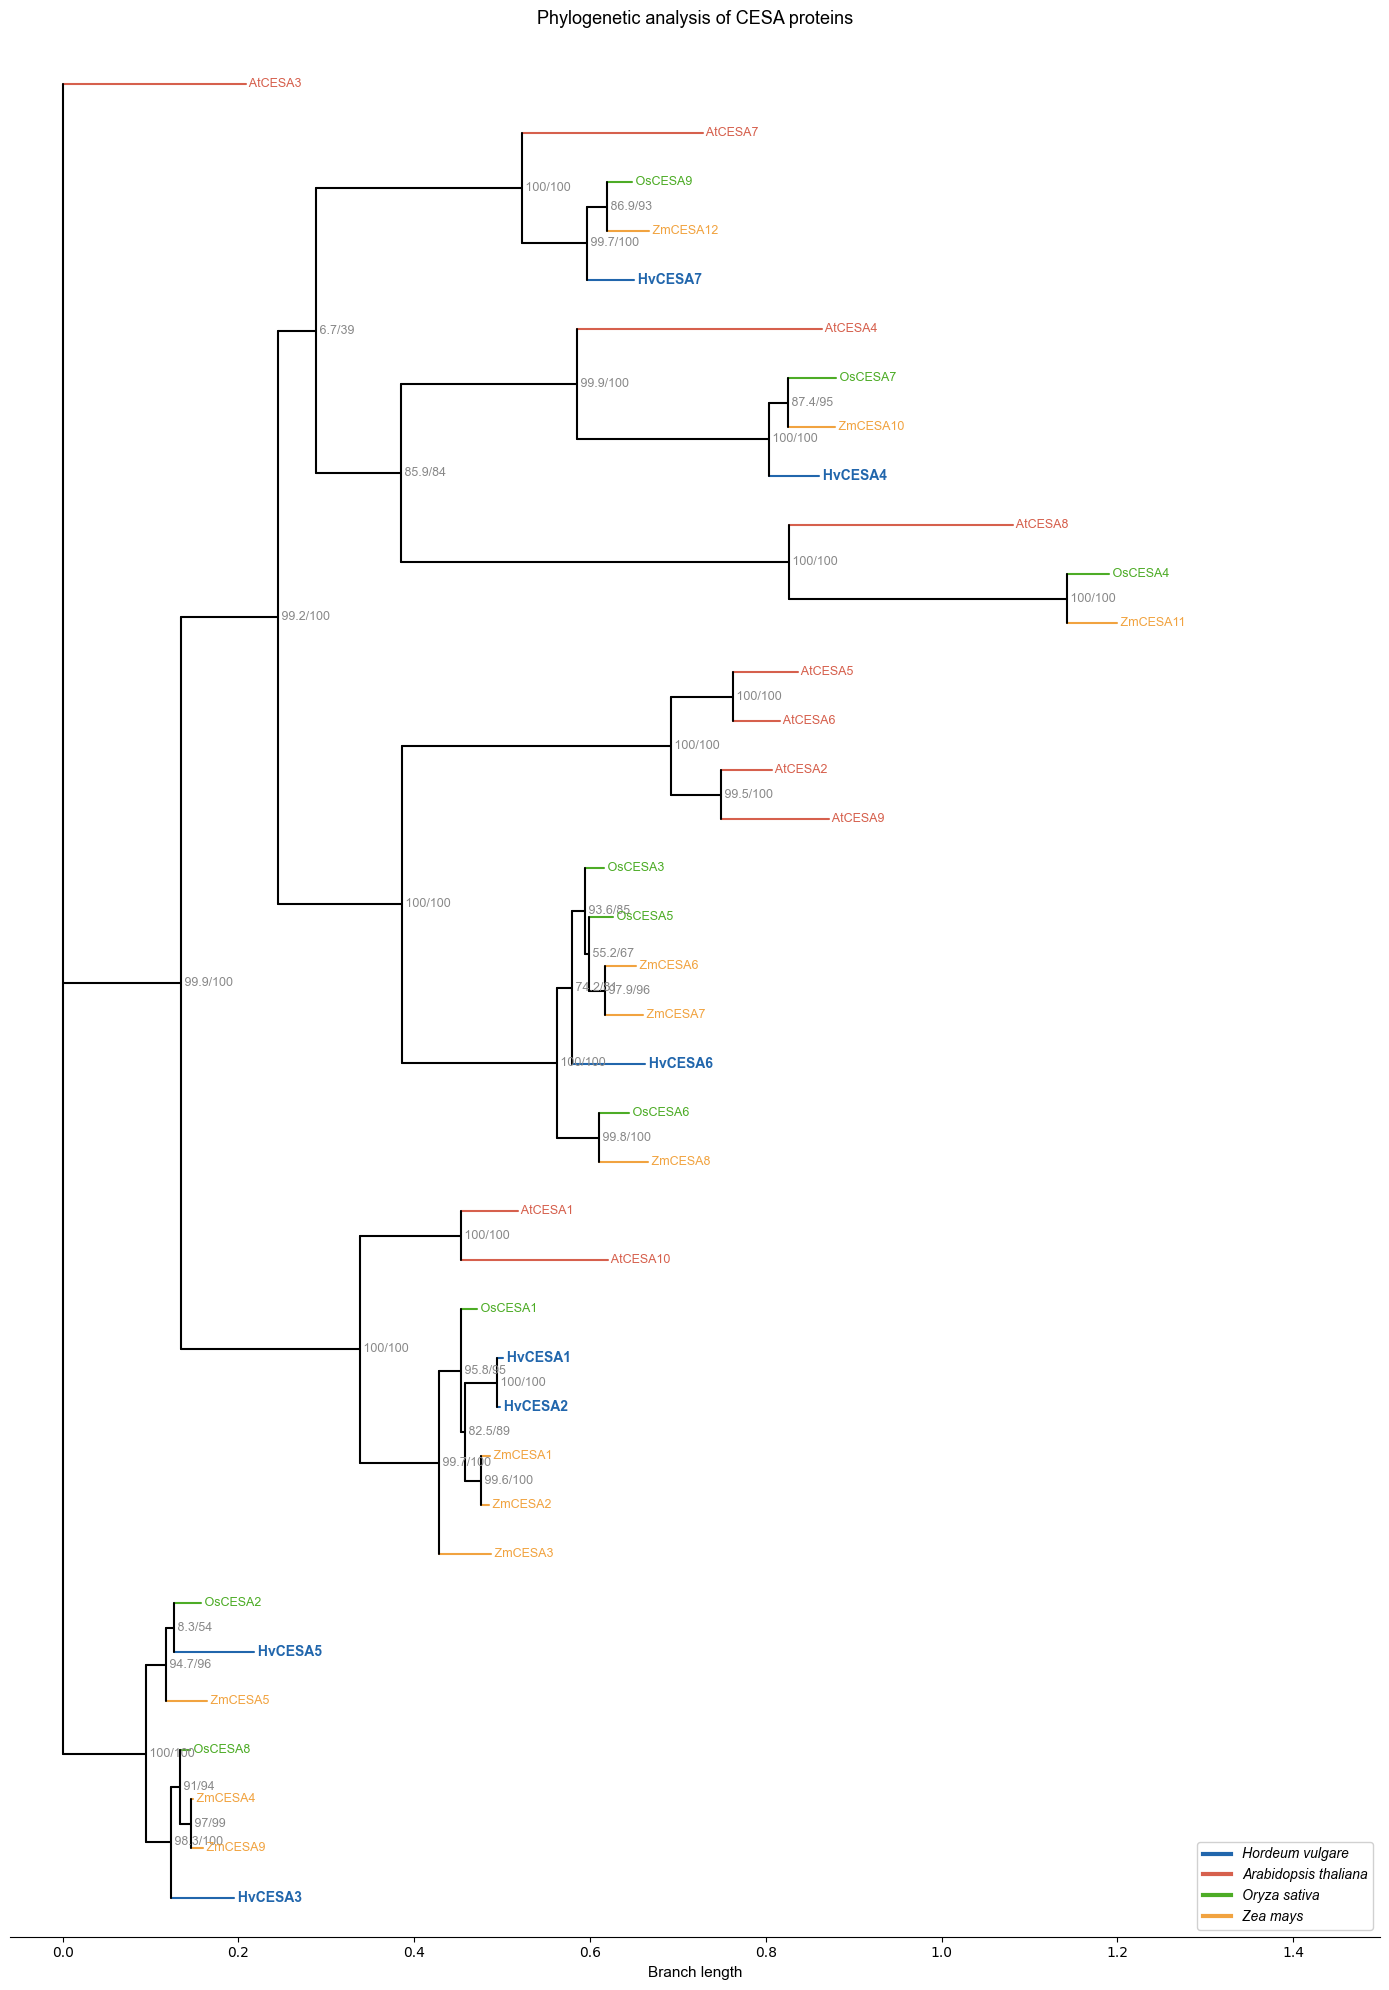

Tree displayed


In [15]:
# STEP 7: Draw publication-quality tree
fig, ax = plt.subplots(figsize=(14, 20))

Phylo.draw(
    tree,
    axes=ax,
    do_show=False,
    label_func=lambda x: x.name if x.name else '',
)

# Style tip labels by species color
for text in ax.texts:
    label = text.get_text().strip()
    color = get_color(label)
    text.set_color(color)
    text.set_fontsize(9)
    text.set_fontfamily('Arial')
    # Bold HvCESA labels
    if label.startswith('Hv'):
        text.set_fontweight('bold')
        text.set_fontsize(10)

# Clean up axes
ax.set_xlabel('Branch length', fontsize=11, fontfamily='Arial')
ax.set_ylabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_yticks([])
ax.set_title('Phylogenetic analysis of CESA proteins', 
             fontsize=13, fontfamily='Arial', pad=15)

# Add legend
legend_elements = [
    Line2D([0], [0], color='#2166ac', linewidth=3, label='Hordeum vulgare'),
    Line2D([0], [0], color='#d6604d', linewidth=3, label='Arabidopsis thaliana'),
    Line2D([0], [0], color='#4dac26', linewidth=3, label='Oryza sativa'),
    Line2D([0], [0], color='#f1a340', linewidth=3, label='Zea mays'),
]
ax.legend(
    handles=legend_elements,
    loc='lower right',
    fontsize=10,
    frameon=True,
    framealpha=0.9,
    prop={'family': 'Arial', 'size': 10, 'style': 'italic'}
)

plt.tight_layout()
plt.show()
print('Tree displayed')

In [17]:
# STEP 8: Export publication-ready figures
fig.savefig('phylogenetic_tree_HvCESA.svg', 
            format='svg', dpi=300, bbox_inches='tight')
fig.savefig('phylogenetic_tree_HvCESA.pdf', 
            format='pdf', dpi=300, bbox_inches='tight')
fig.savefig('phylogenetic_tree_HvCESA.png', 
            format='png', dpi=300, bbox_inches='tight')
print('Exported:')
print('  phylogenetic_tree_HvCESA.svg')
print('  phylogenetic_tree_HvCESA.pdf')
print('  phylogenetic_tree_HvCESA.png')

Exported:
  phylogenetic_tree_HvCESA.svg
  phylogenetic_tree_HvCESA.pdf
  phylogenetic_tree_HvCESA.png


In [19]:
# Check tip order in tree
tips_ordered = [c.name for c in tree.get_terminals()]
for i, tip in enumerate(tips_ordered):
    print(f'{i+1:2d}. {tip}')

 1. AtCESA3
 2. AtCESA7
 3. OsCESA9
 4. ZmCESA12
 5. HvCESA7
 6. AtCESA4
 7. OsCESA7
 8. ZmCESA10
 9. HvCESA4
10. AtCESA8
11. OsCESA4
12. ZmCESA11
13. AtCESA5
14. AtCESA6
15. AtCESA2
16. AtCESA9
17. OsCESA3
18. OsCESA5
19. ZmCESA6
20. ZmCESA7
21. HvCESA6
22. OsCESA6
23. ZmCESA8
24. AtCESA1
25. AtCESA10
26. OsCESA1
27. HvCESA1
28. HvCESA2
29. ZmCESA1
30. ZmCESA2
31. ZmCESA3
32. OsCESA2
33. HvCESA5
34. ZmCESA5
35. OsCESA8
36. ZmCESA4
37. ZmCESA9
38. HvCESA3


In [23]:
# Find closest relatives for each HvCESA
from Bio import Phylo

hv_sequences = ['HvCESA1', 'HvCESA2', 'HvCESA3', 
                'HvCESA4', 'HvCESA5', 'HvCESA6', 'HvCESA7']

for hv in hv_sequences:
    # Find the clade containing this HvCESA
    target = tree.find_any(hv)
    
    # Get the parent clade and its terminals
    path = tree.get_path(hv)
    
    # Look at immediate parent (closest relatives)
    if len(path) >= 2:
        parent = path[-2]
        sisters = [c.name for c in parent.get_terminals() if c.name != hv]
        print(f'{hv}: {sisters}')
    print()

HvCESA1: ['HvCESA2']

HvCESA2: ['HvCESA1']

HvCESA3: ['OsCESA8', 'ZmCESA4', 'ZmCESA9']

HvCESA4: ['OsCESA7', 'ZmCESA10']

HvCESA5: ['OsCESA2']

HvCESA6: ['OsCESA3', 'OsCESA5', 'ZmCESA6', 'ZmCESA7']

HvCESA7: ['OsCESA9', 'ZmCESA12']



In [25]:
# Expand one more level up to get fuller clade picture
for hv in hv_sequences:
    path = tree.get_path(hv)
    
    # Go two levels up for broader clade
    if len(path) >= 3:
        grandparent = path[-3]
        relatives = [c.name for c in grandparent.get_terminals() if c.name != hv]
        print(f'{hv} broader clade: {relatives}')
    print()

HvCESA1 broader clade: ['HvCESA2', 'ZmCESA1', 'ZmCESA2']

HvCESA2 broader clade: ['HvCESA1', 'ZmCESA1', 'ZmCESA2']

HvCESA3 broader clade: ['OsCESA2', 'HvCESA5', 'ZmCESA5', 'OsCESA8', 'ZmCESA4', 'ZmCESA9']

HvCESA4 broader clade: ['AtCESA4', 'OsCESA7', 'ZmCESA10']

HvCESA5 broader clade: ['OsCESA2', 'ZmCESA5']

HvCESA6 broader clade: ['OsCESA3', 'OsCESA5', 'ZmCESA6', 'ZmCESA7', 'OsCESA6', 'ZmCESA8']

HvCESA7 broader clade: ['AtCESA7', 'OsCESA9', 'ZmCESA12']



In [27]:
# Go three levels up to capture At sequences
for hv in hv_sequences:
    path = tree.get_path(hv)
    
    # Go three levels up
    if len(path) >= 4:
        great_grandparent = path[-4]
        relatives = [c.name for c in great_grandparent.get_terminals() if c.name != hv]
        print(f'{hv} full clade: {relatives}')
    print()

HvCESA1 full clade: ['OsCESA1', 'HvCESA2', 'ZmCESA1', 'ZmCESA2']

HvCESA2 full clade: ['OsCESA1', 'HvCESA1', 'ZmCESA1', 'ZmCESA2']


HvCESA4 full clade: ['AtCESA4', 'OsCESA7', 'ZmCESA10', 'AtCESA8', 'OsCESA4', 'ZmCESA11']

HvCESA5 full clade: ['OsCESA2', 'ZmCESA5', 'OsCESA8', 'ZmCESA4', 'ZmCESA9', 'HvCESA3']

HvCESA6 full clade: ['AtCESA5', 'AtCESA6', 'AtCESA2', 'AtCESA9', 'OsCESA3', 'OsCESA5', 'ZmCESA6', 'ZmCESA7', 'OsCESA6', 'ZmCESA8']

HvCESA7 full clade: ['AtCESA7', 'OsCESA9', 'ZmCESA12', 'AtCESA4', 'OsCESA7', 'ZmCESA10', 'HvCESA4', 'AtCESA8', 'OsCESA4', 'ZmCESA11']



In [29]:
# Check specific cases individually
for hv in hv_sequences:
    path = tree.get_path(hv)
    print(f'{hv} - path length: {len(path)}')
    
    # Try all levels
    for level in range(2, min(len(path), 7)):
        ancestor = path[-level]
        relatives = [c.name for c in ancestor.get_terminals() if c.name != hv]
        at_in_clade = [r for r in relatives if r.startswith('At')]
        if at_in_clade:
            print(f'  Level {level}: At sequences found: {at_in_clade}')
            print(f'  Full clade: {relatives}')
            break
    print()

HvCESA1 - path length: 7
  Level 6: At sequences found: ['AtCESA1', 'AtCESA10']
  Full clade: ['AtCESA1', 'AtCESA10', 'OsCESA1', 'HvCESA2', 'ZmCESA1', 'ZmCESA2', 'ZmCESA3']

HvCESA2 - path length: 7
  Level 6: At sequences found: ['AtCESA1', 'AtCESA10']
  Full clade: ['AtCESA1', 'AtCESA10', 'OsCESA1', 'HvCESA1', 'ZmCESA1', 'ZmCESA2', 'ZmCESA3']

HvCESA3 - path length: 3

HvCESA4 - path length: 7
  Level 3: At sequences found: ['AtCESA4']
  Full clade: ['AtCESA4', 'OsCESA7', 'ZmCESA10']

HvCESA5 - path length: 4

HvCESA6 - path length: 6
  Level 4: At sequences found: ['AtCESA5', 'AtCESA6', 'AtCESA2', 'AtCESA9']
  Full clade: ['AtCESA5', 'AtCESA6', 'AtCESA2', 'AtCESA9', 'OsCESA3', 'OsCESA5', 'ZmCESA6', 'ZmCESA7', 'OsCESA6', 'ZmCESA8']

HvCESA7 - path length: 6
  Level 3: At sequences found: ['AtCESA7']
  Full clade: ['AtCESA7', 'OsCESA9', 'ZmCESA12']



In [31]:
# Check HvCESA3 and HvCESA5 specifically - try all levels
for hv in ['HvCESA3', 'HvCESA5']:
    path = tree.get_path(hv)
    print(f'{hv} - path length: {len(path)}')
    for level in range(2, len(path)+1):
        ancestor = path[-level]
        relatives = [c.name for c in ancestor.get_terminals() if c.name != hv]
        print(f'  Level {level}: {relatives}')
    print()

HvCESA3 - path length: 3
  Level 2: ['OsCESA8', 'ZmCESA4', 'ZmCESA9']
  Level 3: ['OsCESA2', 'HvCESA5', 'ZmCESA5', 'OsCESA8', 'ZmCESA4', 'ZmCESA9']

HvCESA5 - path length: 4
  Level 2: ['OsCESA2']
  Level 3: ['OsCESA2', 'ZmCESA5']
  Level 4: ['OsCESA2', 'ZmCESA5', 'OsCESA8', 'ZmCESA4', 'ZmCESA9', 'HvCESA3']



In [33]:
# Check what's one level above the HvCESA3/HvCESA5 clade
for hv in ['HvCESA3', 'HvCESA5']:
    path = tree.get_path(hv)
    # Get the root-level ancestor
    root_clade = path[0]
    relatives = [c.name for c in root_clade.get_terminals()]
    print(f'{hv} root clade members: {relatives}')
    print()

# Also check which AtCESA sequences are NOT in any HvCESA clade yet
all_assigned = [
    'AtCESA1', 'AtCESA10',           # HvCESA1/2 clade
    'AtCESA4', 'AtCESA8',            # HvCESA4 clade  
    'AtCESA5', 'AtCESA6', 'AtCESA2', 'AtCESA9',  # HvCESA6 clade
    'AtCESA7',                        # HvCESA7 clade
]
all_at = ['AtCESA1','AtCESA2','AtCESA3','AtCESA4','AtCESA5',
          'AtCESA6','AtCESA7','AtCESA8','AtCESA9','AtCESA10']
unassigned = [a for a in all_at if a not in all_assigned]
print(f'Unassigned AtCESA sequences: {unassigned}')

HvCESA3 root clade members: ['OsCESA2', 'HvCESA5', 'ZmCESA5', 'OsCESA8', 'ZmCESA4', 'ZmCESA9', 'HvCESA3']

HvCESA5 root clade members: ['OsCESA2', 'HvCESA5', 'ZmCESA5', 'OsCESA8', 'ZmCESA4', 'ZmCESA9', 'HvCESA3']

Unassigned AtCESA sequences: ['AtCESA3']


In [35]:
# Find exactly where AtCESA3 sits relative to HvCESA3/5
path_at3 = tree.get_path('AtCESA3')
print(f'AtCESA3 path length: {len(path_at3)}')
for level in range(2, len(path_at3)+1):
    ancestor = path_at3[-level]
    relatives = [c.name for c in ancestor.get_terminals() if c.name != 'AtCESA3']
    print(f'  Level {level}: {relatives}')
    print()

AtCESA3 path length: 1


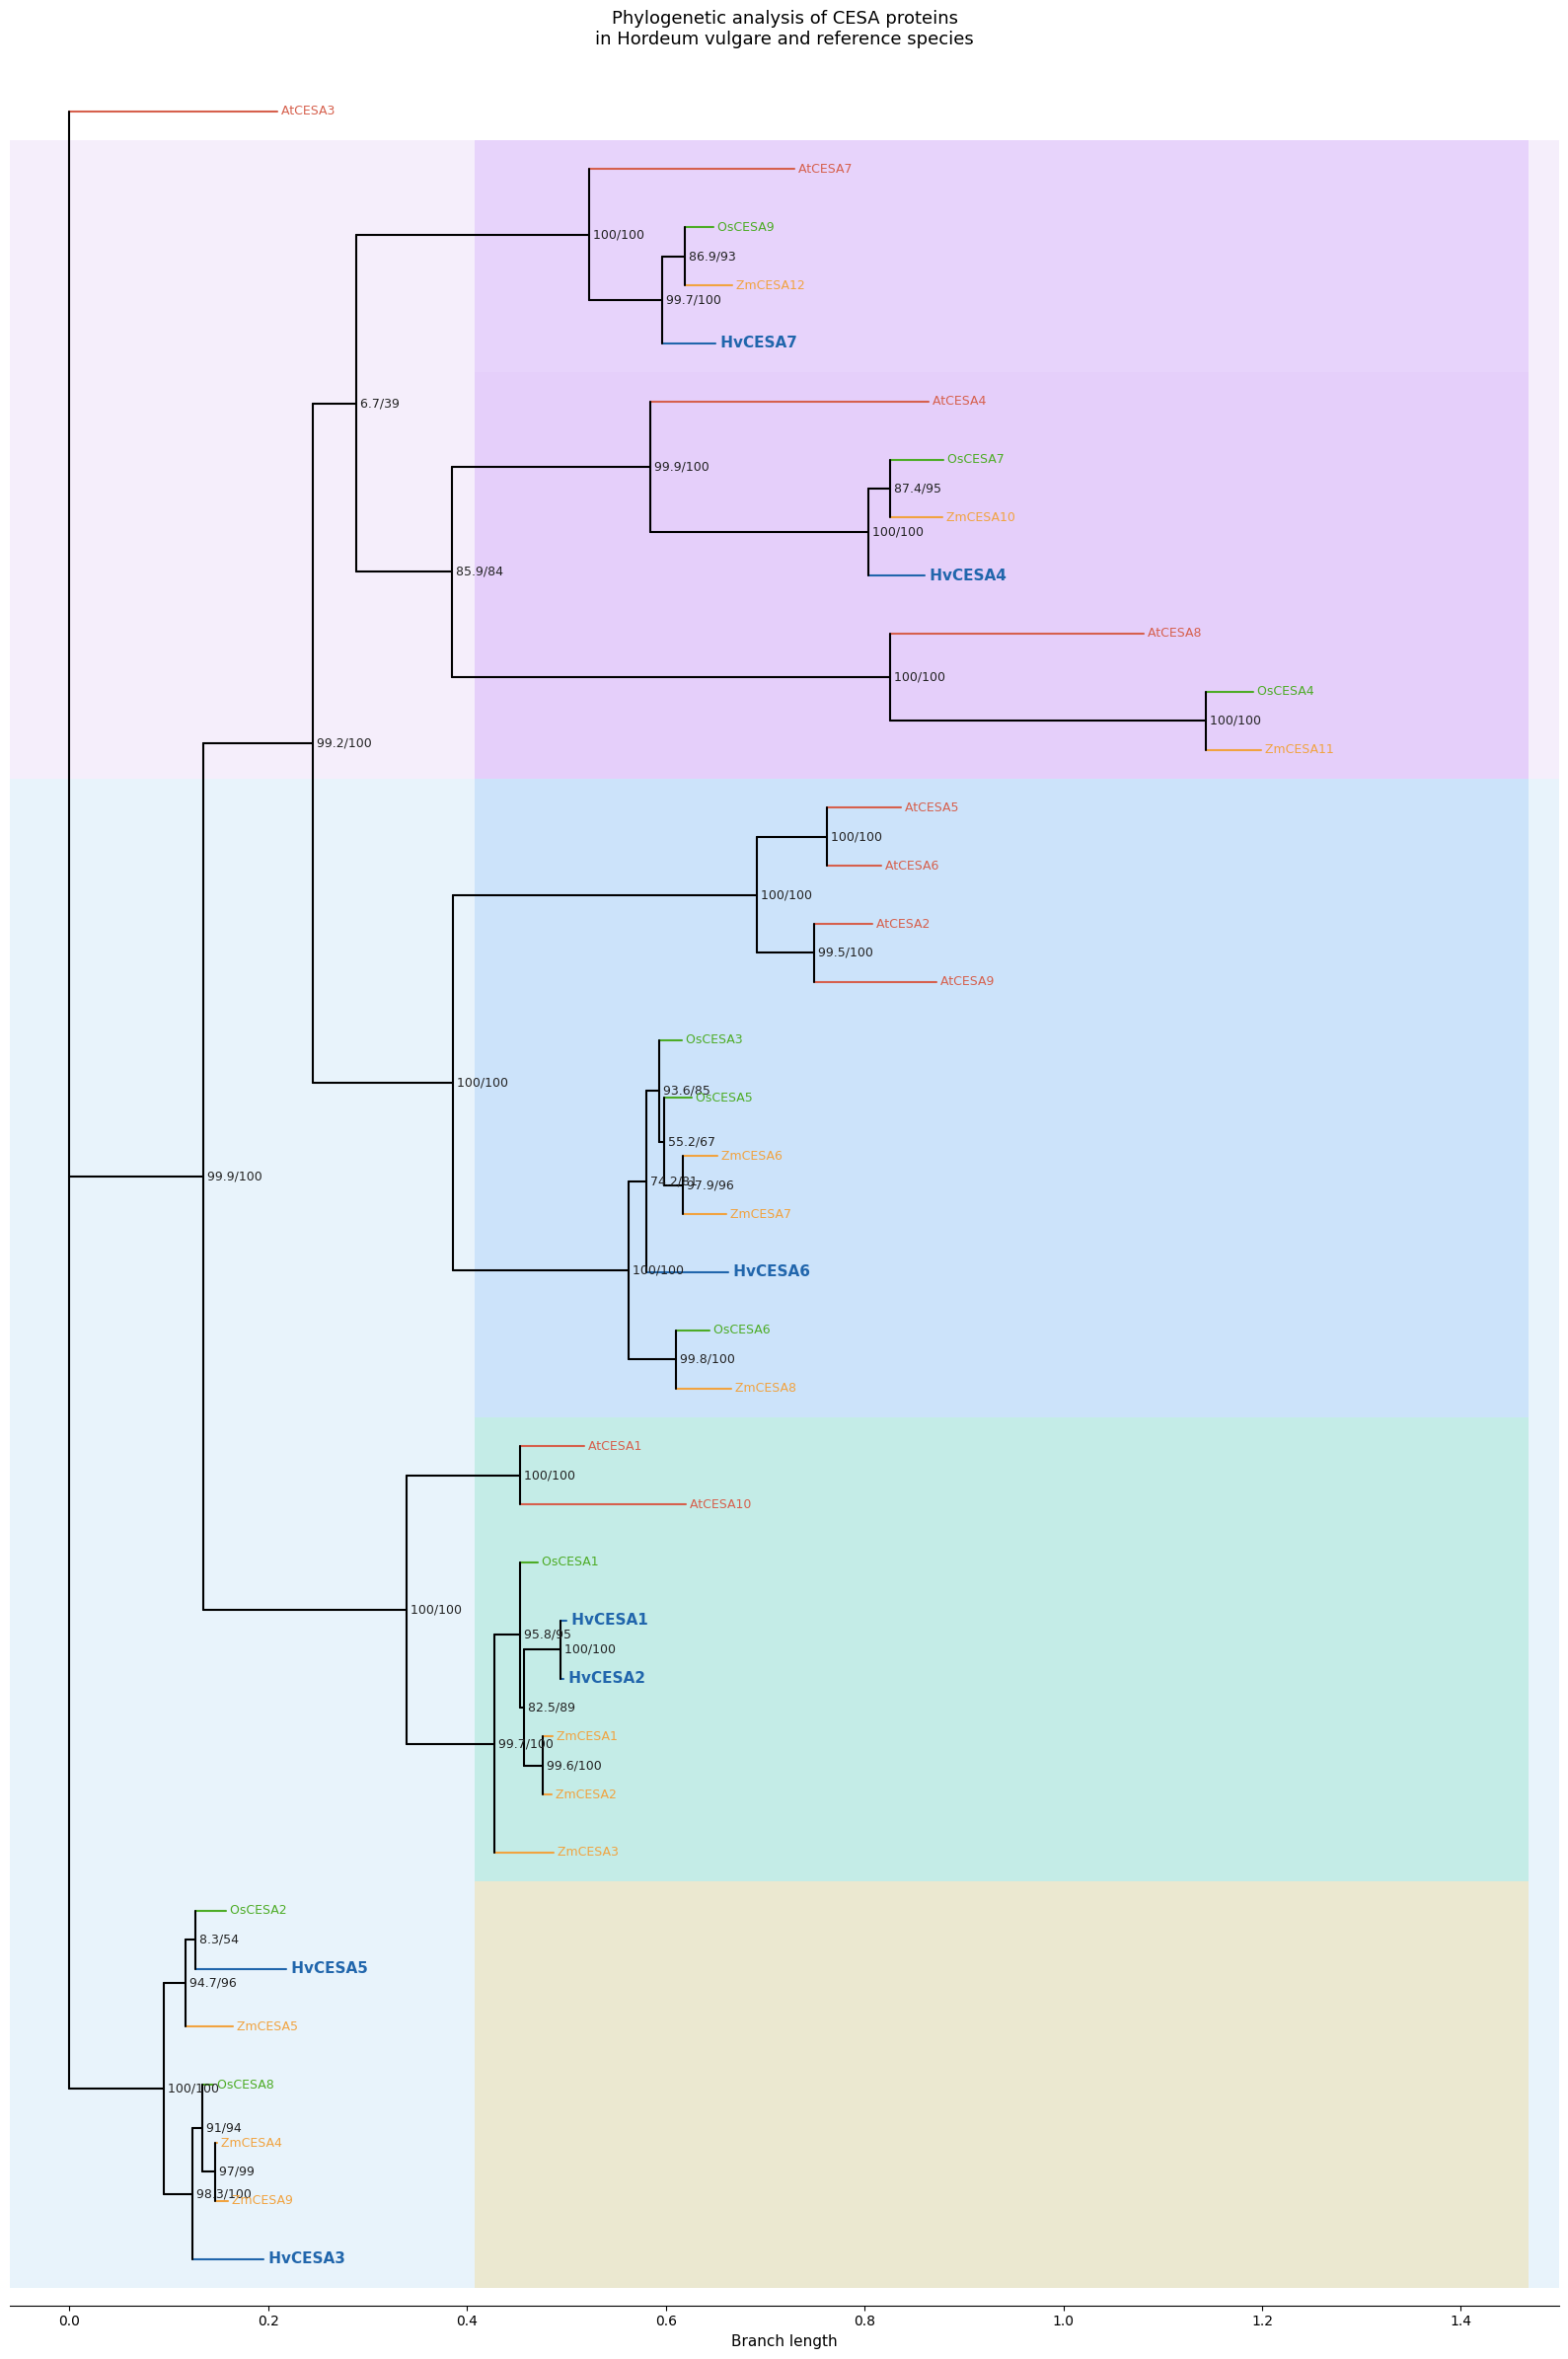

Tree displayed


In [43]:
# STEP 7 FINAL: Publication-quality tree with correct clade shading

fig, ax = plt.subplots(figsize=(16, 24))

# Draw base tree
Phylo.draw(
    tree,
    axes=ax,
    do_show=False,
    label_func=lambda x: x.name if x.name else '',
)

# -------------------------------------------------------
# Color and style tip labels
# -------------------------------------------------------
color_map = {
    'Hv': '#2166ac',   # Blue   - Hordeum vulgare
    'At': '#d6604d',   # Red    - Arabidopsis thaliana
    'Os': '#4dac26',   # Green  - Oryza sativa
    'Zm': '#f1a340',   # Orange - Zea mays
}

def get_color(name):
    for prefix, color in color_map.items():
        if name and name.startswith(prefix):
            return color
    return '#222222'

for text in ax.texts:
    label = text.get_text().strip()
    color = get_color(label)
    text.set_color(color)
    text.set_fontsize(9)
    if label.startswith('Hv'):
        text.set_fontweight('bold')
        text.set_fontsize(11)

# -------------------------------------------------------
# Clade shading based on verified tip positions
# Tip order (y position 1=bottom to 38=top):
#  1. AtCESA3  (outgroup - no shading)
#  2. AtCESA7
#  3. OsCESA9
#  4. ZmCESA12
#  5. HvCESA7   <- Secondary: HvCESA7 clade (tips 2-5)
#  6. AtCESA4
#  7. OsCESA7
#  8. ZmCESA10
#  9. HvCESA4   <- Secondary: HvCESA4 clade (tips 6-9)
# 10. AtCESA8
# 11. OsCESA4
# 12. ZmCESA11  <- Secondary: AtCESA8 subclade (tips 10-12)
# 13. AtCESA5
# 14. AtCESA6
# 15. AtCESA2
# 16. AtCESA9
# 17. OsCESA3
# 18. OsCESA5
# 19. ZmCESA6
# 20. ZmCESA7
# 21. HvCESA6   <- Primary: HvCESA6 clade (tips 13-23)
# 22. OsCESA6
# 23. ZmCESA8
# 24. AtCESA1
# 25. AtCESA10
# 26. OsCESA1
# 27. HvCESA1   <- Primary: HvCESA1/2 clade (tips 24-31)
# 28. HvCESA2
# 29. ZmCESA1
# 30. ZmCESA2
# 31. ZmCESA3
# 32. OsCESA2
# 33. HvCESA5   <- Primary: HvCESA3/5 clade (tips 32-38)
# 34. ZmCESA5
# 35. OsCESA8
# 36. ZmCESA4
# 37. ZmCESA9
# 38. HvCESA3
# -------------------------------------------------------

xmin, xmax = ax.get_xlim()

# --- Secondary cell wall shading (tips 2-12) ---
ax.axhspan(1.5, 12.5,
           facecolor='#e8d5f5',
           alpha=0.4, zorder=0)

# --- Primary cell wall shading (tips 13-38) ---
ax.axhspan(12.5, 38.5,
           facecolor='#c6e2f7',
           alpha=0.4, zorder=0)

# --- Sub-clade shading for each HvCESA group ---

# HvCESA7 subclade (tips 2-5)
ax.axhspan(1.5, 5.5,
           xmin=0.3, xmax=0.98,
           facecolor='#c084fc',
           alpha=0.25, zorder=1)

# HvCESA4 subclade (tips 6-12)
ax.axhspan(5.5, 12.5,
           xmin=0.3, xmax=0.98,
           facecolor='#a855f7',
           alpha=0.2, zorder=1)

# HvCESA6 subclade (tips 13-23)
ax.axhspan(12.5, 23.5,
           xmin=0.3, xmax=0.98,
           facecolor='#60a5fa',
           alpha=0.2, zorder=1)

# HvCESA1/2 subclade (tips 24-31)
ax.axhspan(23.5, 31.5,
           xmin=0.3, xmax=0.98,
           facecolor='#34d399',
           alpha=0.2, zorder=1)

# HvCESA3/5 subclade (tips 32-38)
ax.axhspan(31.5, 38.5,
           xmin=0.3, xmax=0.98,
           facecolor='#fbbf24',
           alpha=0.2, zorder=1)


# -------------------------------------------------------
# Clean up axes
# -------------------------------------------------------
ax.set_xlabel('Branch length', fontsize=11)
ax.set_ylabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_yticks([])
ax.set_title('Phylogenetic analysis of CESA proteins\nin Hordeum vulgare and reference species',
             fontsize=13, pad=15)

# -------------------------------------------------------
# Legend
# -------------------------------------------------------
legend_elements = [
    # Species colors
    Line2D([0], [0], color='#2166ac', linewidth=3, label='Hordeum vulgare'),
    Line2D([0], [0], color='#d6604d', linewidth=3, label='Arabidopsis thaliana'),
    Line2D([0], [0], color='#4dac26', linewidth=3, label='Oryza sativa'),
    Line2D([0], [0], color='#f1a340', linewidth=3, label='Zea mays'),
    # Subclade shading
    mpatches.Patch(facecolor='#60a5fa', alpha=0.5, edgecolor='#60a5fa', label='HvCESA6 clade (primary)'),
    mpatches.Patch(facecolor='#34d399', alpha=0.5, edgecolor='#34d399', label='HvCESA1/2 clade (primary)'),
    mpatches.Patch(facecolor='#fbbf24', alpha=0.5, edgecolor='#fbbf24', label='HvCESA3/5 clade (primary)'),
    mpatches.Patch(facecolor='#c084fc', alpha=0.5, edgecolor='#c084fc', label='HvCESA7 clade (secondary)'),
    mpatches.Patch(facecolor='#a855f7', alpha=0.5, edgecolor='#a855f7', label='HvCESA4 clade (secondary)'),
]

plt.tight_layout()
plt.show()
print('Tree displayed')

In [39]:
# Save as PDF, SVG and PNG
fig.savefig('phylogenetic_tree_HvCESA.pdf', 
            format='pdf', dpi=300, bbox_inches='tight')
print('Saved successfully')

Saved successfully


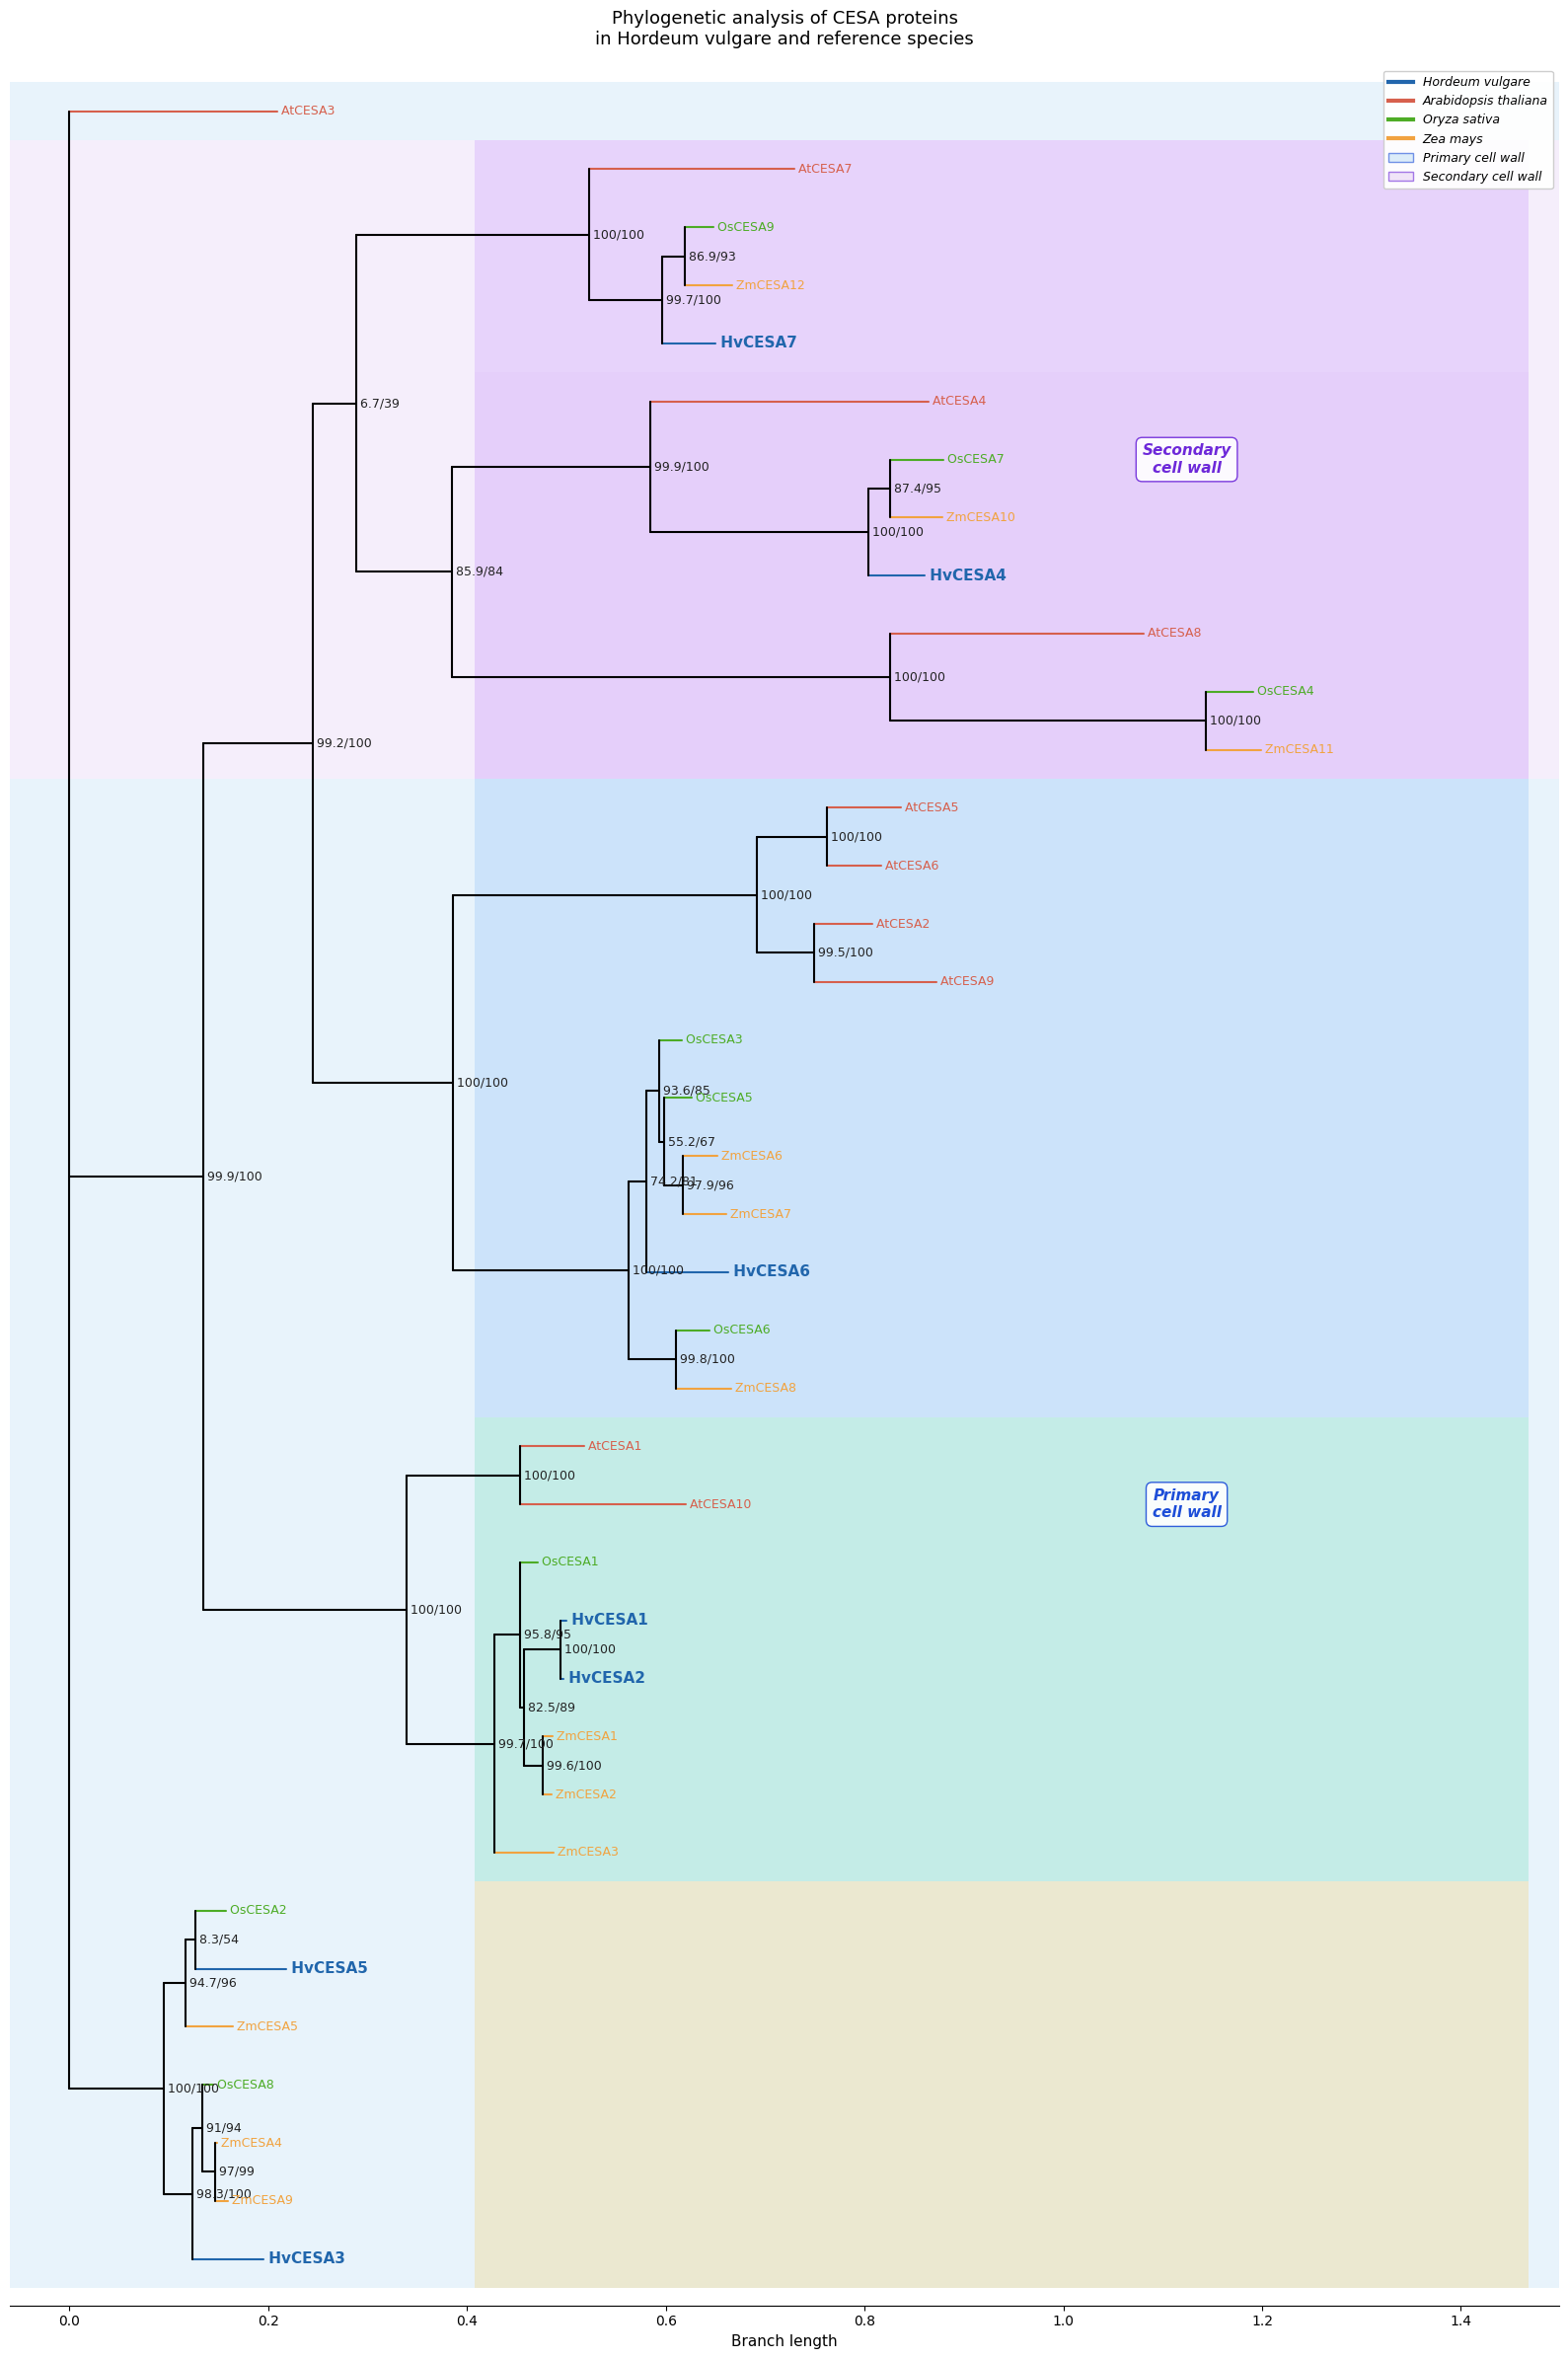

Tree displayed
Saved: PDF, SVG, PNG


In [59]:
# STEP 7 FINAL: Publication-quality tree with correct clade shading

fig, ax = plt.subplots(figsize=(16, 24))

# Draw base tree
Phylo.draw(
    tree,
    axes=ax,
    do_show=False,
    label_func=lambda x: x.name if x.name else '',
)

# -------------------------------------------------------
# Color and style tip labels
# -------------------------------------------------------
color_map = {
    'Hv': '#2166ac',   # Blue   - Hordeum vulgare
    'At': '#d6604d',   # Red    - Arabidopsis thaliana
    'Os': '#4dac26',   # Green  - Oryza sativa
    'Zm': '#f1a340',   # Orange - Zea mays
}

def get_color(name):
    for prefix, color in color_map.items():
        if name and name.startswith(prefix):
            return color
    return '#222222'

for text in ax.texts:
    label = text.get_text().strip()
    color = get_color(label)
    text.set_color(color)
    text.set_fontsize(9)
    if label.startswith('Hv'):
        text.set_fontweight('bold')
        text.set_fontsize(11)

# -------------------------------------------------------
# Clade shading based on verified tip positions
# Tip order (y position 1=bottom to 38=top):
#  1. AtCESA3  (outgroup - primary cell wall)
#  2. AtCESA7
#  3. OsCESA9
#  4. ZmCESA12
#  5. HvCESA7
#  6. AtCESA4
#  7. OsCESA7
#  8. ZmCESA10
#  9. HvCESA4
# 10. AtCESA8
# 11. OsCESA4
# 12. ZmCESA11
# 13. AtCESA5
# 14. AtCESA6
# 15. AtCESA2
# 16. AtCESA9
# 17. OsCESA3
# 18. OsCESA5
# 19. ZmCESA6
# 20. ZmCESA7
# 21. HvCESA6
# 22. OsCESA6
# 23. ZmCESA8
# 24. AtCESA1
# 25. AtCESA10
# 26. OsCESA1
# 27. HvCESA1
# 28. HvCESA2
# 29. ZmCESA1
# 30. ZmCESA2
# 31. ZmCESA3
# 32. OsCESA2
# 33. HvCESA5
# 34. ZmCESA5
# 35. OsCESA8
# 36. ZmCESA4
# 37. ZmCESA9
# 38. HvCESA3
# -------------------------------------------------------

xmin, xmax = ax.get_xlim()

# --- AtCESA3 outgroup - primary cell wall shading (tip 1) ---
ax.axhspan(0.5, 1.5,
           facecolor='#c6e2f7',
           alpha=0.4, zorder=0)

# --- Secondary cell wall shading (tips 2-12) ---
ax.axhspan(1.5, 12.5,
           facecolor='#e8d5f5',
           alpha=0.4, zorder=0)

# --- Primary cell wall shading (tips 13-38) ---
ax.axhspan(12.5, 38.5,
           facecolor='#c6e2f7',
           alpha=0.4, zorder=0)

# --- Sub-clade shading for each HvCESA group ---

# HvCESA7 subclade (tips 2-5)
ax.axhspan(1.5, 5.5,
           xmin=0.3, xmax=0.98,
           facecolor='#c084fc',
           alpha=0.25, zorder=1)

# HvCESA4 subclade (tips 6-12)
ax.axhspan(5.5, 12.5,
           xmin=0.3, xmax=0.98,
           facecolor='#a855f7',
           alpha=0.2, zorder=1)

# HvCESA6 subclade (tips 13-23)
ax.axhspan(12.5, 23.5,
           xmin=0.3, xmax=0.98,
           facecolor='#60a5fa',
           alpha=0.2, zorder=1)

# HvCESA1/2 subclade (tips 24-31)
ax.axhspan(23.5, 31.5,
           xmin=0.3, xmax=0.98,
           facecolor='#34d399',
           alpha=0.2, zorder=1)

# HvCESA3/5 subclade (tips 32-38)
ax.axhspan(31.5, 38.5,
           xmin=0.3, xmax=0.98,
           facecolor='#fbbf24',
           alpha=0.2, zorder=1)

# -------------------------------------------------------
# Main clade labels on right side
# -------------------------------------------------------
x_right = xmax * 0.75

ax.text(x_right, 7.0, 'Secondary\ncell wall',
        fontsize=11, fontstyle='italic', fontweight='bold',
        color='#6d28d9', va='center', ha='center',
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='white', edgecolor='#6d28d9', alpha=0.9))

ax.text(x_right, 25.0, 'Primary\ncell wall',
        fontsize=11, fontstyle='italic', fontweight='bold',
        color='#1d4ed8', va='center', ha='center',
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='white', edgecolor='#1d4ed8', alpha=0.9))

# -------------------------------------------------------
# Clean up axes
# -------------------------------------------------------
ax.set_xlabel('Branch length', fontsize=11)
ax.set_ylabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_yticks([])
ax.set_title('Phylogenetic analysis of CESA proteins\nin Hordeum vulgare and reference species',
             fontsize=13, pad=15)

# -------------------------------------------------------
# Legend
# -------------------------------------------------------
legend_elements = [
    Line2D([0], [0], color='#2166ac', linewidth=3,
           label='Hordeum vulgare'),
    Line2D([0], [0], color='#d6604d', linewidth=3,
           label='Arabidopsis thaliana'),
    Line2D([0], [0], color='#4dac26', linewidth=3,
           label='Oryza sativa'),
    Line2D([0], [0], color='#f1a340', linewidth=3,
           label='Zea mays'),
    mpatches.Patch(facecolor='#c6e2f7', alpha=0.6,
                   edgecolor='#1d4ed8',
                   label='Primary cell wall'),
    mpatches.Patch(facecolor='#e8d5f5', alpha=0.6,
                   edgecolor='#6d28d9',
                   label='Secondary cell wall'),
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=9,
    frameon=True,
    framealpha=0.95,
    prop={'family': 'DejaVu Sans', 'size': 9, 'style': 'italic'}
)

plt.tight_layout()
plt.show()
print('Tree displayed')

# -------------------------------------------------------
# Export
# -------------------------------------------------------
fig.savefig('phylogenetic_tree_HvCESA.pdf',
            format='pdf', dpi=300, bbox_inches='tight')
fig.savefig('phylogenetic_tree_HvCESA.svg',
            format='svg', dpi=300, bbox_inches='tight')
fig.savefig('phylogenetic_tree_HvCESA.png',
            format='png', dpi=300, bbox_inches='tight')
print('Saved: PDF, SVG, PNG')
